# 05 · Statistical Analysis (Hypothesis Testing)
**Milestone 5 — Kenyan Retail Customer & Sales Intelligence Capstone**

The EDA in Milestone 3 *suggested* several patterns. This notebook asks whether they are **statistically significant**,
meaning unlikely to be explained by random variation alone.

| # | Business question | Main test |
|---|---|---|
| Q1 | Do promotional discounts significantly increase sales? | Mann-Whitney U (within each category), bootstrap confidence intervals |
| Q2 | Is average customer spending significantly different across stores? | Kruskal-Wallis + Welch ANOVA on log values, Holm-corrected post-hoc tests |
| Q3 | Is purchasing behaviour significantly different across product categories? | Kruskal-Wallis (units per line), chi-square (payment method, time of day) |

**Procedure for every test:**
1. State H₀ and H₁.
2. Choose the unit of analysis.
3. Check the assumptions.
4. Choose a test that suits them.
5. Use **α = 0.05**.
6. Report the statistic, the p-value, an **effect size** and a **95% confidence interval**.
7. Interpret the result and draw the business implication.

> **Two principles:**
> - **Statistical significance is not the same as importance.** With thousands of rows, tiny differences become
>   "significant", so effect sizes are always reported.
> - **This is observational data.** Promotions were not randomly assigned, so the results describe *associations*,
>   not proven causes.

Reusable test functions live in `src/analysis/stats_tests.py`.

In [1]:
# --- Setup: make the project's "src" package importable from this notebook ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import style

style.apply_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats
from src.analysis import eda, stats_tests as st

sales = eda.load_analytical()
orders = eda.orders_table(sales)
ALPHA = st.ALPHA
results = []          # collects one summary row per hypothesis test for the final table
print(f"{len(sales):,} sales lines, {len(orders):,} orders, alpha = {ALPHA}")

2,988 sales lines, 2,650 orders, alpha = 0.05


# Q1. Do promotional discounts significantly increase sales?

**Defining "sales".** The discount lowers the price, so revenue per line is a misleading measure. The question is
whether customers buy **more units**. Two complementary measures are used:
- **Primary:** *units per sales line*. Does a customer buy more of a product when it is discounted?
- **Secondary:** *units per day* of a category on its campaign days compared with other days.

**Why compare within each category?** Promotions are concentrated in certain categories (for example beverages and
groceries), and those categories are naturally bought in multiples. A pooled comparison would partly measure
*category mix*, so each category is also tested separately.

**Hypotheses (units per line):**
- **H₀:** the distribution of units per line is the same for promotion and full-price lines.
- **H₁:** promotion lines tend to have **more** units (one-sided, because the business question is about an increase).

## Q1.1 Assumption checks

,group,n,mean,median,std,skewness,shapiro_p,normal_at_5pct
0,Promotion lines,315,2.04,2.00,3.44,15.34,0.00,False
1,Full-price lines,2673,1.55,1.00,1.25,19.78,0.00,False


Levene (Brown-Forsythe) test for equal variances: p = 3.21e-06


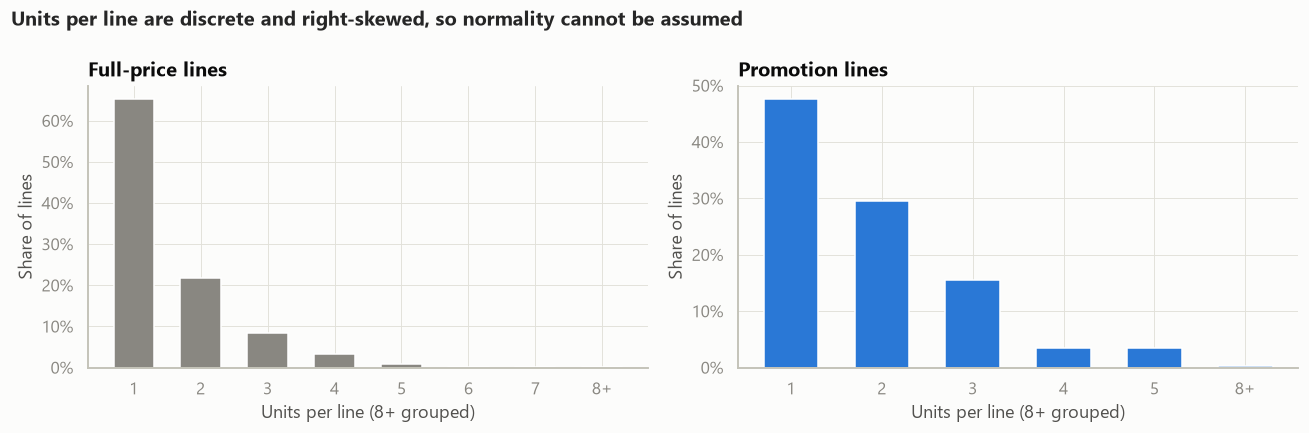

In [3]:
promo_units = sales.loc[sales["is_promo"], "quantity"]
full_units = sales.loc[~sales["is_promo"], "quantity"]
checks = st.assumption_checks({"Promotion lines": promo_units, "Full-price lines": full_units})
display(checks.round(4))
print(f"Levene (Brown-Forsythe) test for equal variances: p = {checks.attrs['levene_p']:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, data, colour) in zip(axes, [("Full-price lines", full_units, style.NEUTRAL),
                                            ("Promotion lines", promo_units, style.SERIES[0])]):
    counts = data.clip(upper=8).value_counts().sort_index()
    ax.bar(counts.index.astype(str).str.replace("8", "8+"), counts.values / counts.sum(), color=colour, width=0.6)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(label)
    ax.set_xlabel("Units per line (8+ grouped)")
    ax.set_ylabel("Share of lines")
fig.suptitle("Units per line are discrete and right-skewed, so normality cannot be assumed",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
style.save(fig, "m5_q1_distribution")
plt.show()

**Assumption results:**
- Units per line are **whole numbers** (mostly 1–3).
- They are **heavily right-skewed** (skewness 15–20, because of a few bulk purchases).
- Shapiro-Wilk rejects normality (p < 0.001), and Levene rejects equal variances (p < 0.001).

**Test choice:** a t-test assumes roughly normal data and is sensitive to outliers. The **Mann-Whitney U test** compares
*ranks*, needs no normality and is robust to the bulk-purchase outliers, so it is the primary test. A **Welch t-test** is
reported only as a robustness check. The 95% confidence interval for the difference in mean units comes from the
**bootstrap**, which also needs no normality.

## Q1.2 Pooled test: all promotion lines vs all full-price lines

In [4]:
mw = st.mann_whitney(promo_units, full_units, alternative="greater")
wt = st.welch_t(promo_units, full_units, alternative="greater")
diff, lo, hi = st.bootstrap_ci(promo_units, full_units)

print(f"Mean units: promotion {promo_units.mean():.2f} vs full price {full_units.mean():.2f}")
print(f"Median units: promotion {promo_units.median():.0f} vs full price {full_units.median():.0f}")
print(f"Mann-Whitney U = {mw['statistic']:,.0f}, one-sided p = {mw['p_value']:.2e}, rank-biserial r = {mw['effect_size']:.3f}")
print(f"Welch t = {wt['statistic']:.2f}, one-sided p = {wt['p_value']:.4f}   (robustness check)")
print(f"Difference in mean units per line: {diff:.2f}  (95% bootstrap CI {lo:.2f} to {hi:.2f})")
results.append({"question": "Q1", "hypothesis": "Promotion lines have more units per line (pooled)",
                "test": "Mann-Whitney U (one-sided)", "statistic": mw["statistic"], "p_value": mw["p_value"],
                "effect_size": f"r = {mw['effect_size']:.2f}", "ci_95": f"+{diff:.2f} units ({lo:.2f} to {hi:.2f})"})

Mean units: promotion 2.04 vs full price 1.55
Median units: promotion 2 vs full price 1
Mann-Whitney U = 500,594, one-sided p = 6.71e-11, rank-biserial r = 0.189
Welch t = 2.51, one-sided p = 0.0062   (robustness check)
Difference in mean units per line: 0.49  (95% bootstrap CI 0.21 to 0.93)


## Q1.3 Within-category tests (controls for category mix)

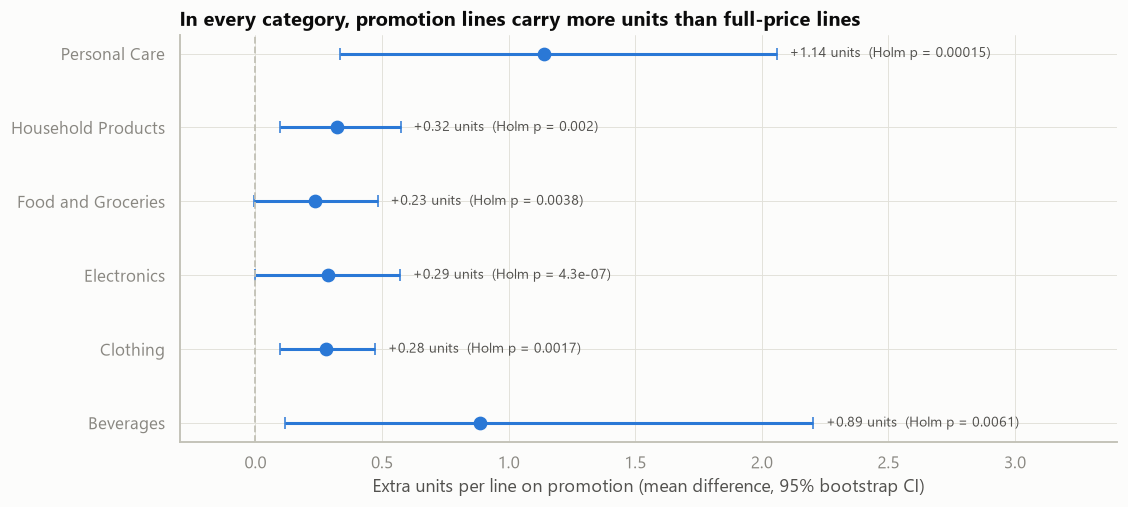

,category,promo_lines,full_price_lines,mean_units_promo,mean_units_full,difference,ci_low,ci_high,p_value,rank_biserial_r,p_holm,significant
0,Beverages,98,575,2.59,1.71,0.89,0.12,2.20,0.01,0.14,0.01,True
1,Clothing,62,239,1.52,1.24,0.28,0.10,0.47,0.00,0.20,0.00,True
2,Electronics,7,97,1.29,1.00,0.29,0.00,0.57,0.00,0.29,0.00,True
3,Food and Groceries,95,1011,2.03,1.80,0.23,-0.01,0.48,0.00,0.16,0.00,True
4,Household Products,43,406,1.58,1.26,0.32,0.10,0.57,0.00,0.22,0.00,True
5,Personal Care,10,345,2.40,1.26,1.14,0.33,2.06,0.00,0.53,0.00,True


In [5]:
rows = []
for category in sorted(sales["category"].unique()):
    d = sales[sales["category"] == category]
    a, b = d.loc[d["is_promo"], "quantity"], d.loc[~d["is_promo"], "quantity"]
    res = st.mann_whitney(a, b, alternative="greater")
    est, low, high = st.bootstrap_ci(a, b)
    rows.append({"category": category, "promo_lines": len(a), "full_price_lines": len(b),
                 "mean_units_promo": a.mean(), "mean_units_full": b.mean(),
                 "difference": est, "ci_low": low, "ci_high": high,
                 "p_value": res["p_value"], "rank_biserial_r": res["effect_size"]})
by_cat = pd.DataFrame(rows)
by_cat["p_holm"] = st.holm(by_cat["p_value"])        # 6 tests -> correct for multiple comparisons
by_cat["significant"] = by_cat["p_holm"] < ALPHA

fig, ax = plt.subplots(figsize=(11, 4.8))
y = np.arange(len(by_cat))
ax.errorbar(by_cat["difference"], y, xerr=[by_cat["difference"] - by_cat["ci_low"], by_cat["ci_high"] - by_cat["difference"]],
            fmt="o", color=style.SERIES[0], ecolor=style.SERIES[0], elinewidth=2, capsize=4, markersize=8)
ax.axvline(0, color=style.INK["axis"], linewidth=1.2, linestyle="--")
ax.set_yticks(y, by_cat["category"])
for yi, (d, p) in enumerate(zip(by_cat["difference"], by_cat["p_holm"])):
    ax.text(by_cat["ci_high"].iloc[yi] + 0.05, yi, f"+{d:.2f} units  (Holm p = {p:.2g})", va="center",
            color=style.INK["secondary"], fontsize=9)
ax.set_xlim(-0.3, by_cat["ci_high"].max() + 1.2)
ax.set_title("In every category, promotion lines carry more units than full-price lines")
ax.set_xlabel("Extra units per line on promotion (mean difference, 95% bootstrap CI)")
style.save(fig, "m5_q1_by_category")
plt.show()
by_cat.round(4)

**Interpretation:**
- **Pooled:** promotion lines average **2.04 units, against 1.55** at full price, a difference of **+0.49 units per line
  (95% CI 0.21 to 0.93)**. Mann-Whitney p < 0.001, with a *small* effect size (r = 0.19). The Welch t-test agrees (p = 0.006).
- **Within categories:** the result holds in **all six categories** after Holm correction (adjusted p ≤ 0.007).
  The extra units range from about +0.23 (groceries) to +1.14 (personal care).

**Caveats:**
- The groceries bootstrap interval just touches zero (−0.01 to 0.48), although the rank test is significant. The two
  measure slightly different things: the rank test detects a general shift towards buying 2–3 units, while the mean is
  pulled around by the full-price 48-bag sugar purchase.
- Electronics and personal care have only 7 and 10 promotion lines, so their intervals are wide.

## Q1.4 Sensitivity check: excluding the two genuine bulk purchases

The 60-bottle water purchase was itself a promotion line, while the 48-bag sugar purchase was at full price. Both were
kept in Milestone 2 because they are real. Here we check that the conclusion does not depend on them.

In [6]:
bulk = sales["quantity"] >= 40
trimmed = sales[~bulk]
print("Excluded lines:", sales.loc[bulk, ["transaction_id", "product_name", "quantity", "is_promo"]].to_dict("records"))
a, b = trimmed.loc[trimmed["is_promo"], "quantity"], trimmed.loc[~trimmed["is_promo"], "quantity"]
mw_t = st.mann_whitney(a, b, alternative="greater")
d_t, lo_t, hi_t = st.bootstrap_ci(a, b)
print(f"Without bulk purchases: mean {a.mean():.2f} vs {b.mean():.2f}; difference {d_t:.2f} (95% CI {lo_t:.2f} to {hi_t:.2f}); "
      f"Mann-Whitney p = {mw_t['p_value']:.2e}, r = {mw_t['effect_size']:.3f}")

bev = trimmed[trimmed["category"] == "Beverages"]
mw_b = st.mann_whitney(bev.loc[bev["is_promo"], "quantity"], bev.loc[~bev["is_promo"], "quantity"], "greater")
print(f"Beverages without the 60-bottle line: mean {bev.loc[bev['is_promo'], 'quantity'].mean():.2f} vs "
      f"{bev.loc[~bev['is_promo'], 'quantity'].mean():.2f}, p = {mw_b['p_value']:.4f}")

Excluded lines: [{'transaction_id': 'TXN00208', 'product_name': 'White Sugar', 'quantity': 48, 'is_promo': False}, {'transaction_id': 'TXN00328', 'product_name': 'Bottled Water', 'quantity': 60, 'is_promo': True}]


Without bulk purchases: mean 1.85 vs 1.53; difference 0.32 (95% CI 0.21 to 0.45); Mann-Whitney p = 1.13e-10, r = 0.187
Beverages without the 60-bottle line: mean 2.00 vs 1.71, p = 0.0096


**Result:** without the two bulk lines, promotion lines still carry significantly more units, and the confidence
interval no longer has a long upper tail. The conclusion is **robust**: it does not rest on a single unusual purchase.

## Q1.5 Secondary measure: category demand on campaign days

**H₀:** a category's daily units are the same on its campaign days and on other days.
**H₁:** daily units are higher on campaign days (one-sided).

Days with zero sales are included, and each category is compared only with its own non-campaign days.

In [7]:
calendar_days = pd.date_range(config.START_DATE, config.END_DATE, freq="D")
promos = pd.read_csv(config.CLEANED_DIR / "promotions.csv", parse_dates=["start_date", "end_date"])
rows = []
for category in sorted(sales["category"].unique()):
    units = sales[sales["category"] == category].groupby("transaction_date")["quantity"].sum()
    units = units.reindex(calendar_days, fill_value=0)
    on_campaign = pd.Series(False, index=calendar_days)
    for p in promos[promos["target_category"] == category].itertuples():
        on_campaign[(calendar_days >= p.start_date) & (calendar_days <= p.end_date)] = True
    res = st.mann_whitney(units[on_campaign], units[~on_campaign], alternative="greater")
    est, low, high = st.bootstrap_ci(units[on_campaign], units[~on_campaign])
    rows.append({"category": category, "campaign_days": int(on_campaign.sum()),
                 "units_per_day_campaign": units[on_campaign].mean(), "units_per_day_other": units[~on_campaign].mean(),
                 "difference": est, "ci_low": low, "ci_high": high, "p_value": res["p_value"]})
daily = pd.DataFrame(rows)
daily["p_holm"] = st.holm(daily["p_value"])
daily["significant"] = daily["p_holm"] < ALPHA
results.append({"question": "Q1", "hypothesis": "Category units per day are higher on campaign days",
                "test": "Mann-Whitney U per category (Holm)", "statistic": np.nan, "p_value": np.nan,
                "effect_size": f"{daily['significant'].sum()} of 6 categories significant",
                "ci_95": "see per-category table",
                "decision": f"Reject H0 in {daily['significant'].sum()} of 6 categories"})
daily.round(4)

,category,campaign_days,units_per_day_campaign,units_per_day_other,difference,ci_low,ci_high,p_value,p_holm,significant
0,Beverages,53,4.79,1.45,3.35,1.61,5.99,0.00,0.00,True
1,Clothing,84,1.12,0.46,0.66,0.37,0.97,0.00,0.00,True
2,Electronics,14,0.64,0.14,0.51,0.09,0.94,0.00,0.00,True
3,Food and Groceries,49,3.94,2.66,1.27,0.29,2.31,0.01,0.01,True
4,Household Products,36,1.89,0.74,1.15,0.43,1.95,0.00,0.00,True
5,Personal Care,16,1.50,0.61,0.89,-0.14,2.07,0.25,0.25,False


**Interpretation:** five of the six categories sell significantly more units per day during their campaigns (Holm
p ≤ 0.013). Beverages show the largest increase: about **4.8 against 1.4 units per day**, +3.3 units (95% CI 1.6 to 6.0).
**Personal care is not significant** (p = 0.25). It had only 16 campaign days, so the test has little power.

**Why this measure is weaker:** campaigns are scheduled in seasonal peaks (back-to-school, Easter, December), so some of
the campaign-day increase is seasonal demand that would have happened anyway. The *units-per-line* result (Q1.3) is less
exposed to this, because it compares customers who bought the same category in the same period.

### Q1 conclusion and business implication
**Reject H₀.** Promotion lines are associated with significantly larger purchases: about half an extra unit per line
overall, and in every category. **This does not prove causation:** promotions were not randomly assigned, and they
coincide with seasonal peaks.

- Promotions do move volume, but Milestone 3 showed that grocery and electronics discounts eat almost all the margin.
  The extra half unit does not pay for a 10–20% discount on a 12–19% margin.
- To measure the *true* causal effect, Duka Bora should run a **controlled test**: discount a category in some stores
  and not in others over the same weeks, then compare the two groups.

# Q2. Is average customer spending significantly different across stores?

**Unit of analysis:** the **order** (receipt value), meaning what a customer spends per visit at a given store.
As a robustness check, the analysis is repeated at **customer level** (each customer's total spend, grouped by their
preferred store).

**Hypotheses:**
- **H₀:** order values come from the same distribution in all six stores (no store difference).
- **H₁:** at least one store's order values differ.

## Q2.1 Assumption checks

,group,n,mean,median,std,skewness,shapiro_p,normal_at_5pct
0,Kisumu Town,356,892.43,480.00,"1,620.23",9.34,0.00,False
1,Mombasa Town,458,676.55,410.92,751.09,2.48,0.00,False
2,Nairobi CBD,643,818.00,450.00,"1,287.83",7.47,0.00,False
3,Nakuru Town,371,905.00,468.00,"1,576.96",6.70,0.00,False
4,Thika,340,755.10,438.00,"1,326.67",8.72,0.00,False
5,Westlands,482,898.72,480.00,"1,513.88",9.49,0.00,False


Levene (Brown-Forsythe) test for equal variances: p = 0.188


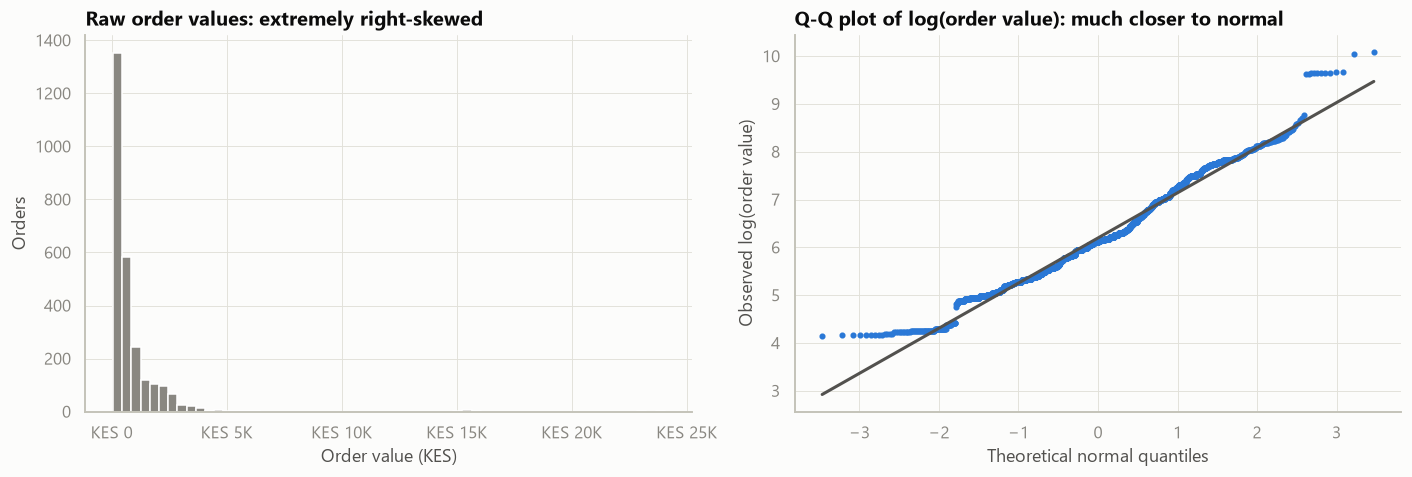

In [8]:
store_groups = {town: g["order_value"].to_numpy() for town, g in orders.groupby("town")}
checks = st.assumption_checks(store_groups)
display(checks.round(3))
print(f"Levene (Brown-Forsythe) test for equal variances: p = {checks.attrs['levene_p']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(orders["order_value"], bins=60, color=style.NEUTRAL)
axes[0].xaxis.set_major_formatter(style.KES_FORMATTER)
axes[0].set_title("Raw order values: extremely right-skewed")
axes[0].set_xlabel("Order value (KES)")
axes[0].set_ylabel("Orders")
stats.probplot(np.log(orders["order_value"]), dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=style.SERIES[0], markersize=3)
axes[1].get_lines()[1].set(color=style.INK["secondary"])
axes[1].set_title("Q-Q plot of log(order value): much closer to normal")
axes[1].set_xlabel("Theoretical normal quantiles")
axes[1].set_ylabel("Observed log(order value)")
fig.tight_layout()
style.save(fig, "m5_q2_assumptions")
plt.show()

**Assumption results:**
- Order values are **far from normal** in every store (skewness 2.5–9.5; Shapiro p < 0.001). A few large electronics
  baskets dominate the means.
- Variances are not significantly different (Levene p = 0.19).
- Taking **logs** makes the distribution much closer to normal, as the Q-Q plot shows.

**Test choice:**
- **Primary: Kruskal-Wallis.** It compares ranks, needs no normality and is robust to large baskets.
- **Support: Welch's ANOVA on log(order value).** It compares typical (geometric-mean) baskets without assuming equal variances.
- **For comparison only: a classical ANOVA on raw values**, to show why test choice matters.
- **Post-hoc:** pairwise Mann-Whitney tests with **Holm correction**. Fifteen pairs at α = 0.05 would otherwise carry a
  roughly 54% risk of at least one false positive.

## Q2.2 Test results

,test,statistic,p_value,effect_size,effect_measure,significant_at_5pct
0,One-way ANOVA (raw values),1.99,0.08,NaN,NaN,False
1,Welch ANOVA (log values),3.17,0.01,NaN,NaN,True
2,Kruskal-Wallis H,13.86,0.02,0.00,epsilon-squared,True


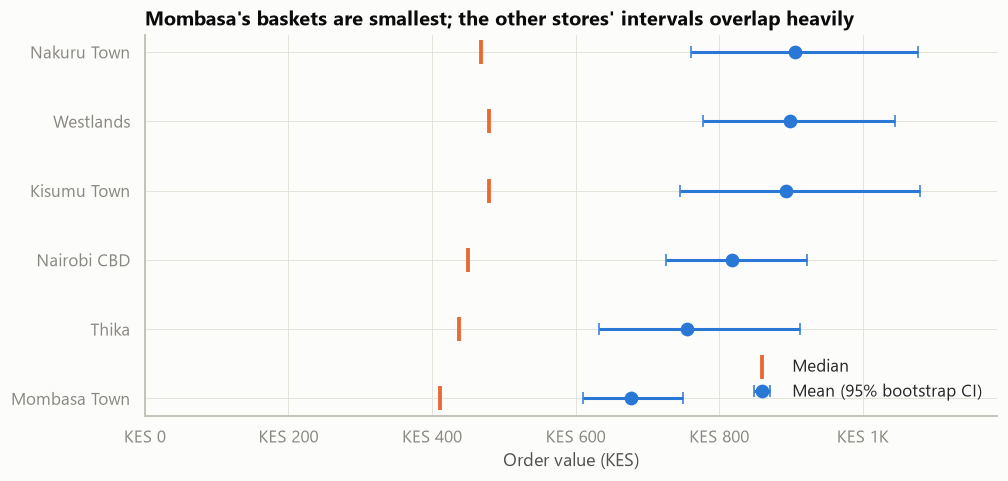

,store,mean_order_value,ci_low,ci_high,median_order_value
1,Mombasa Town,676.60,610.70,748.90,410.90
4,Thika,755.10,633.20,912.60,438.00
2,Nairobi CBD,818.00,726.30,922.20,450.00
0,Kisumu Town,892.40,745.50,"1,079.50",480.00
5,Westlands,898.70,776.90,"1,045.40",480.00
3,Nakuru Town,905.00,760.60,"1,077.50",468.00


In [9]:
tests = pd.DataFrame([st.one_way_anova(store_groups), st.welch_anova(store_groups, log=True),
                      st.kruskal_wallis(store_groups)])
tests["significant_at_5pct"] = tests["p_value"] < ALPHA
display(tests[["test", "statistic", "p_value", "effect_size", "effect_measure", "significant_at_5pct"]].round(4))

kw = st.kruskal_wallis(store_groups)
results.append({"question": "Q2", "hypothesis": "Order value differs across stores",
                "test": "Kruskal-Wallis H", "statistic": kw["statistic"], "p_value": kw["p_value"],
                "effect_size": f"epsilon-squared = {kw['effect_size']:.3f}", "ci_95": "see store CI chart"})

# Mean order value per store with 95% bootstrap CIs
ci = pd.DataFrame([(town, *st.bootstrap_ci(v), np.median(v)) for town, v in store_groups.items()],
                  columns=["store", "mean_order_value", "ci_low", "ci_high", "median_order_value"]).sort_values("mean_order_value")
fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(ci))
ax.errorbar(ci["mean_order_value"], y, xerr=[ci["mean_order_value"] - ci["ci_low"], ci["ci_high"] - ci["mean_order_value"]],
            fmt="o", color=style.SERIES[0], elinewidth=2, capsize=4, markersize=8, label="Mean (95% bootstrap CI)")
ax.scatter(ci["median_order_value"], y, marker="|", s=250, color=style.SERIES[1], linewidths=2.5, label="Median", zorder=3)
ax.set_yticks(y, ci["store"])
ax.xaxis.set_major_formatter(style.KES_FORMATTER)
ax.set_xlim(0, ci["ci_high"].max() * 1.1)
ax.set_title("Mombasa's baskets are smallest; the other stores' intervals overlap heavily")
ax.set_xlabel("Order value (KES)")
ax.legend(loc="lower right")
style.save(fig, "m5_q2_store_ci")
plt.show()
ci.round(1)

In [10]:
posthoc = st.pairwise_mann_whitney(orders, "town", "order_value")
display(posthoc.round(4))

# Robustness: customer-level total spend by preferred store
customers = eda.customer_summary(sales).merge(
    pd.read_csv(config.CLEANED_DIR / "customers.csv")[["customer_id", "preferred_store_id"]], on="customer_id")
kw_cust = st.kruskal_wallis({s: g["spend"] for s, g in customers.groupby("preferred_store_id")})
print(f"Customer-level total spend by preferred store: Kruskal-Wallis H = {kw_cust['statistic']:.2f}, p = {kw_cust['p_value']:.3f}")
results.append({"question": "Q2", "hypothesis": "Customer total spend differs by preferred store (robustness)",
                "test": "Kruskal-Wallis H", "statistic": kw_cust["statistic"], "p_value": kw_cust["p_value"],
                "effect_size": f"epsilon-squared = {max(kw_cust['effect_size'], 0):.3f}", "ci_95": "-"})

,group_1,group_2,median_1,median_2,p_value,rank_biserial_r,p_holm,significant
0,Mombasa Town,Westlands,410.92,480.00,0.00,-0.13,0.01,True
1,Kisumu Town,Mombasa Town,480.00,410.92,0.01,0.10,0.17,False
2,Mombasa Town,Nakuru Town,410.92,468.00,0.02,-0.10,0.24,False
3,Thika,Westlands,438.00,480.00,0.04,-0.08,0.51,False
4,Mombasa Town,Nairobi CBD,410.92,450.00,0.05,-0.07,0.53,False
5,Kisumu Town,Nakuru Town,480.00,468.00,0.84,0.01,1.00,False
6,Kisumu Town,Thika,480.00,438.00,0.17,0.06,1.00,False
7,Kisumu Town,Nairobi CBD,480.00,450.00,0.38,0.03,1.00,False
8,Mombasa Town,Thika,410.92,438.00,0.24,-0.05,1.00,False
9,Kisumu Town,Westlands,480.00,480.00,0.64,-0.02,1.00,False


Customer-level total spend by preferred store: Kruskal-Wallis H = 2.40, p = 0.791


**Interpretation:**
- **Test choice changes the conclusion.** The classical ANOVA on raw values finds **no** significant difference
  (p = 0.076): a few huge electronics baskets inflate the within-store variance and hide the pattern. Both tests suited to
  skewed data find a significant difference: **Kruskal-Wallis p = 0.017** and **Welch ANOVA on logs p = 0.008**.
  We therefore **reject H₀**.
- **The effect is very small.** ε² = 0.003 means store explains about 0.3% of the variation in order value. The
  confidence intervals for mean order value overlap heavily.
- **Post-hoc:** after Holm correction, only **Mombasa vs Westlands** differs significantly (adjusted p = 0.013). Mombasa's
  median basket is KES 411, against KES 480 in Westlands.
- **Customer level:** total spend per customer does **not** differ by home store (p = 0.79). Customers spend similar
  amounts over two years wherever they shop. The store effect is about **basket size per visit**.

### Q2 conclusion and business implication
**Reject H₀:** order values differ across stores, but **the difference is small and driven mainly by Mombasa's smaller
baskets**.
- **No need for different pricing or customer strategies by store**, since customers are worth about the same everywhere.
- **For Mombasa, focus on basket building:** bundles, multi-buy offers and add-on displays for beverages, its biggest category.
- **Lesson for reporting:** comparing store *average* baskets directly is misleading, because one TV sale can move a
  store's mean by more than the real difference between stores.

# Q3. Is purchasing behaviour significantly different across product categories?

"Purchasing behaviour" is tested on three dimensions:

| Dimension | Variable | Test |
|---|---|---|
| **How much** customers buy | Units per line | Kruskal-Wallis (6 groups, skewed counts) |
| **How** customers pay | Payment method | Chi-square test of independence |
| **When** customers buy | Time of day (morning, midday, afternoon, evening) | Chi-square test of independence |

All three p-values are Holm-corrected as one family of tests.

**Hypotheses (for each dimension):**
- **H₀:** the behaviour is the same for every category (independent of category).
- **H₁:** at least one category differs.

## Q3.1 How much: units per line by category

,group,n,mean,median,std,skewness,shapiro_p,normal_at_5pct
0,Beverages,673,1.83,1.00,2.44,20.33,0.00,False
1,Clothing,301,1.30,1.00,0.58,1.94,0.00,False
2,Electronics,104,1.02,1.00,0.14,7.00,0.00,False
3,Food and Groceries,1106,1.82,1.00,1.74,17.30,0.00,False
4,Household Products,449,1.29,1.00,0.58,2.07,0.00,False
5,Personal Care,355,1.29,1.00,0.65,2.66,0.00,False


Kruskal-Wallis H = 253.0, p = 1.25e-52, epsilon-squared = 0.083


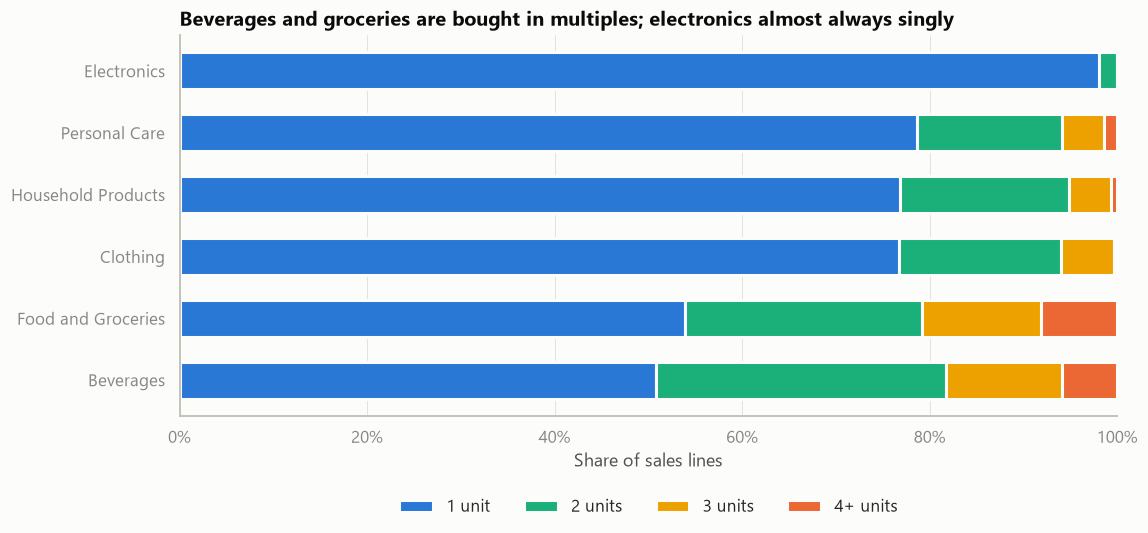

In [11]:
cat_groups = {c: g["quantity"].to_numpy() for c, g in sales.groupby("category")}
display(st.assumption_checks(cat_groups).round(3))
kw_units = st.kruskal_wallis(cat_groups)
print(f"Kruskal-Wallis H = {kw_units['statistic']:.1f}, p = {kw_units['p_value']:.2e}, epsilon-squared = {kw_units['effect_size']:.3f}")

dist = pd.crosstab(sales["category"], sales["quantity"].clip(upper=4), normalize="index")
dist.columns = ["1 unit", "2 units", "3 units", "4+ units"]
dist = dist.sort_values("1 unit")
fig, ax = plt.subplots(figsize=(11, 4.5))
left = np.zeros(len(dist))
for col, colour in zip(dist.columns, [style.SERIES[0], style.SERIES[2], style.SERIES[3], style.SERIES[1]]):
    ax.barh(dist.index, dist[col], left=left, color=colour, height=0.6, label=col,
            edgecolor=style.INK["surface"], linewidth=2)
    left += dist[col].to_numpy()
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Beverages and groceries are bought in multiples; electronics almost always singly")
ax.set_xlabel("Share of sales lines")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.3))
style.save(fig, "m5_q3_units_by_category")
plt.show()

**Assumptions and choice:** units per line are skewed, discrete counts in all six groups (Shapiro p < 0.001), so
Kruskal-Wallis is used rather than ANOVA.

**Result:** H = 253, **p ≈ 10⁻⁵²**, ε² = 0.083 (a small-to-medium effect). About half of beverage and grocery lines
contain 2 or more units, compared with about 22% for clothing, household and personal care, and **2% for electronics**.

## Q3.2 How customers pay: payment method by category

**Independence assumption:** the chi-square test assumes each observation is independent. Lines from the same
multi-item order share one payment method, so they are not fully independent. As a robustness check, the test is
repeated on **single-line orders only** (one line = one independent purchase). There, card and bank transfer are merged
so that every expected count stays at 5 or more.

Observed counts:


payment_method,Bank Transfer,Cash,Debit/Credit Card,M-Pesa
category,,,,
Beverages,32,176,96,368
Clothing,24,66,54,157
Electronics,9,22,25,48
Food and Groceries,44,271,171,617
Household Products,26,99,67,256
Personal Care,21,66,63,203


Chi-square = 28.02, dof = 15, p = 0.0214, Cramer's V = 0.056, minimum expected count = 5.4
Robustness (single-line orders, 3 payment groups): chi-square = 23.48, p = 0.0091, Cramer's V = 0.071, min expected = 12.6


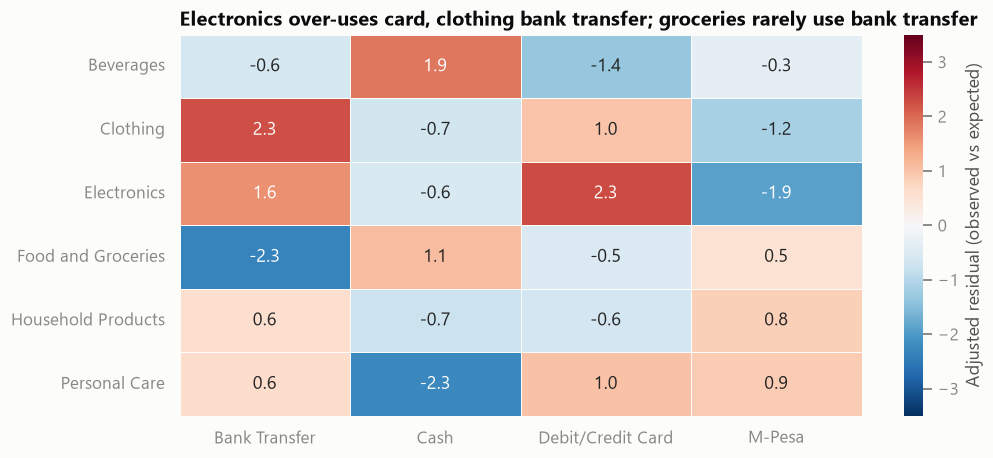

In [12]:
paid = sales[sales["payment_method"] != "Unknown"]       # 7 orders with unknown payment excluded
table = pd.crosstab(paid["category"], paid["payment_method"])
chi_pay = st.chi_square(table)
print("Observed counts:")
display(table)
print(f"Chi-square = {chi_pay['statistic']:.2f}, dof = {chi_pay['dof']}, p = {chi_pay['p_value']:.4f}, "
      f"Cramer's V = {chi_pay['effect_size']:.3f}, minimum expected count = {chi_pay['min_expected']:.1f}")

single = paid[paid["order_lines"] == 1].copy()
single["payment_group"] = single["payment_method"].replace({"Bank Transfer": "Card / Bank", "Debit/Credit Card": "Card / Bank"})
chi_single = st.chi_square(pd.crosstab(single["category"], single["payment_group"]))
print(f"Robustness (single-line orders, 3 payment groups): chi-square = {chi_single['statistic']:.2f}, "
      f"p = {chi_single['p_value']:.4f}, Cramer's V = {chi_single['effect_size']:.3f}, min expected = {chi_single['min_expected']:.1f}")

# Adjusted standardized residuals show WHICH cells drive the result (|value| > 2 = notable)
res = stats.chi2_contingency(table)
expected = res.expected_freq
row_p = table.sum(axis=1).to_numpy()[:, None] / table.to_numpy().sum()
col_p = table.sum(axis=0).to_numpy()[None, :] / table.to_numpy().sum()
adj_resid = (table - expected) / np.sqrt(expected * (1 - row_p) * (1 - col_p))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(adj_resid, cmap=style.DIVERGING, center=0, vmin=-3.5, vmax=3.5, annot=True, fmt=".1f",
            cbar_kws={"label": "Adjusted residual (observed vs expected)"}, linewidths=0.5,
            linecolor=style.INK["surface"], ax=ax)
ax.set_title("Electronics over-uses card, clothing bank transfer; groceries rarely use bank transfer")
ax.set_xlabel("")
ax.set_ylabel("")
style.save(fig, "m5_q3_payment_residuals")
plt.show()

**Result:** χ² = 28.0 (15 degrees of freedom), **p = 0.021**, Cramér's V = **0.056** (a weak association). Every expected
count is at least 5.4. The single-line robustness check agrees: p = 0.009, V = 0.071.

The residual heatmap shows where the difference lies. Cells beyond ±2 are notable:
- **Electronics** is paid by **card** more than expected (+2.3): 24% of its lines, against about 15% overall.
- **Clothing** is paid by **bank transfer** more than expected (+2.3).
- **Groceries** rarely use bank transfer (−2.3).
- **Personal care** uses less cash than expected (−2.3).
- Beverages tilt towards cash (+1.9), but not beyond the threshold.

**M-Pesa dominates in every category (46–58%)**, so the differences are at the margins.

## Q3.3 When customers buy: time of day by category

In [13]:
table_time = pd.crosstab(sales["category"], sales["day_part"])[["Morning", "Midday", "Afternoon", "Evening"]]
chi_time = st.chi_square(table_time)
display((table_time.div(table_time.sum(axis=1), axis=0) * 100).round(1))
print(f"Chi-square = {chi_time['statistic']:.2f}, dof = {chi_time['dof']}, p = {chi_time['p_value']:.3f}, "
      f"Cramer's V = {chi_time['effect_size']:.3f}, min expected = {chi_time['min_expected']:.1f}")

day_part,Morning,Midday,Afternoon,Evening
category,,,,
Beverages,18.70,24.50,17.40,39.40
Clothing,15.00,24.30,20.90,39.90
Electronics,14.40,25.00,14.40,46.20
Food and Groceries,17.70,25.10,19.70,37.40
Household Products,15.10,26.90,21.40,36.50
Personal Care,12.70,26.50,22.80,38.00


Chi-square = 16.89, dof = 15, p = 0.326, Cramer's V = 0.043, min expected = 17.2


**Result:** χ² = 16.9, **p = 0.33**, so we **fail to reject H₀**. There is no evidence that categories are bought at
different times of day. Every category follows the same evening-peak pattern seen in Milestone 3.

In [14]:
family = pd.DataFrame([
    {"dimension": "Units per line", "test": "Kruskal-Wallis H", "statistic": kw_units["statistic"],
     "p_value": kw_units["p_value"], "effect_size": f"epsilon-squared = {kw_units['effect_size']:.3f}"},
    {"dimension": "Payment method", "test": "Chi-square", "statistic": chi_pay["statistic"],
     "p_value": chi_pay["p_value"], "effect_size": f"Cramer's V = {chi_pay['effect_size']:.3f}"},
    {"dimension": "Time of day", "test": "Chi-square", "statistic": chi_time["statistic"],
     "p_value": chi_time["p_value"], "effect_size": f"Cramer's V = {chi_time['effect_size']:.3f}"},
])
family["p_holm"] = st.holm(family["p_value"])
family["significant"] = family["p_holm"] < ALPHA
for _, r in family.iterrows():
    results.append({"question": "Q3", "hypothesis": f"{r['dimension']} differs across categories", "test": r["test"],
                    "statistic": r["statistic"], "p_value": r["p_holm"], "effect_size": r["effect_size"],
                    "ci_95": "-"})
family

,dimension,test,statistic,p_value,effect_size,p_holm,significant
0,Units per line,Kruskal-Wallis H,253.00,0.00,epsilon-squared = 0.083,0.00,True
1,Payment method,Chi-square,28.02,0.02,Cramer's V = 0.056,0.04,True
2,Time of day,Chi-square,16.89,0.33,Cramer's V = 0.043,0.33,False


### Q3 conclusion and business implication
After Holm correction across the three dimensions:
- **How much customers buy differs strongly by category** (reject H₀, adjusted p ≈ 10⁻⁵²).
- **How they pay differs significantly but weakly** (reject H₀, adjusted p = 0.043).
- **When they buy does not differ** (fail to reject H₀, adjusted p = 0.33).

**Implications:**
- **Multi-buy offers ("3 for 2", bundles) suit beverages and groceries,** where customers already buy in multiples.
  For clothing and household goods, aim at *adding* a second item, such as cross-selling.
- **Electronics customers need reliable card and bank-transfer payment,** and possibly instalment options, so card
  terminals should be prioritized in the electronics section. Grocery tills still need good cash handling.
- **Staffing and promotion timing can be the same for all categories,** because category does not change *when*
  people shop.

# Summary of all hypothesis tests

In [15]:
summary = pd.DataFrame(results)
# Rows that summarise several tests carry their own decision text; the rest use p < alpha.
computed = np.where(summary["p_value"] < ALPHA, "Reject H0", "Fail to reject H0")
summary["decision"] = summary["decision"].fillna(pd.Series(computed, index=summary.index))
summary.to_csv(config.REPORTS_DIR / "hypothesis_test_results.csv", index=False)
summary.style.format({"statistic": "{:,.2f}", "p_value": "{:.2e}"}).hide(axis="index")

question,hypothesis,test,statistic,p_value,effect_size,ci_95,decision
Q1,Promotion lines have more units per line (pooled),Mann-Whitney U (one-sided),"500,594.00",6.71e-11,r = 0.19,+0.49 units (0.21 to 0.93),Reject H0
Q1,Category units per day are higher on campaign days,Mann-Whitney U per category (Holm),nan,nan,5 of 6 categories significant,see per-category table,Reject H0 in 5 of 6 categories
Q2,Order value differs across stores,Kruskal-Wallis H,13.86,1.66e-02,epsilon-squared = 0.003,see store CI chart,Reject H0
Q2,Customer total spend differs by preferred store (robustness),Kruskal-Wallis H,2.40,7.91e-01,epsilon-squared = 0.000,-,Fail to reject H0
Q3,Units per line differs across categories,Kruskal-Wallis H,253.00,3.75e-52,epsilon-squared = 0.083,-,Reject H0
Q3,Payment method differs across categories,Chi-square,28.02,4.28e-02,Cramer's V = 0.056,-,Reject H0
Q3,Time of day differs across categories,Chi-square,16.89,3.26e-01,Cramer's V = 0.043,-,Fail to reject H0


| Question | Decision | Effect size | What it means for management |
|---|---|---|---|
| **Q1** Do promotions increase sales? | **Reject H₀** in all 6 categories (units per line) and 5 of 6 (units per day) | Small (r = 0.19; +0.49 units per line) | Promotions move volume, but the gain is too small to justify discounts that exceed category margins. Test causality with a store-level controlled trial |
| **Q2** Does spending differ by store? | **Reject H₀** (order value); fail to reject at customer level | Very small (ε² = 0.003) | Only Mombasa's baskets are clearly smaller. Use basket-building there; no need for store-specific strategies elsewhere |
| **Q3** Does behaviour differ by category? | **Reject H₀** for units per line and payment method; **fail to reject** for time of day | Small to medium (units); weak (payment) | Multi-buy offers for beverages and groceries; card and bank payments for electronics; one staffing plan for all categories |

**Limitations:**
- **Observational, synthetic data.** No result proves causation.
- **Promotions coincide with seasonal peaks,** which may inflate the campaign-day comparison.
- **Small samples.** Electronics (7) and personal care (10) have few promotion lines, which gives wide intervals.
- **Lines in a multi-item order are not fully independent.** This was handled with single-line robustness checks.
- **Multiple testing** was controlled with Holm correction within each question.

**Next:** Milestone 6 builds the demand forecast and the at-risk customer model.